# Análise de tensões e deformações de um talude sob peso próprio (MEF)

Adaptação do notebook *PlastiMatLabStudent* (viga cônica, elementos **LST**, procedimento
incremental) para um **talude** carregado apenas pelo **peso próprio** do solo.

**O que o código faz**

1. Gera uma malha de elementos triangulares de 6 nós (LST) a partir da linha da superfície do talude
   (mesmo formato de entrada do notebook de equilíbrio limite/Bishop).
2. Calcula as forças nodais equivalentes ao peso próprio (força de corpo $b_y=-\gamma$).
3. Aplica a gravidade em **incrementos** ($\lambda = 1/n_{step}, \dots, 1$) com solo
   - **elástico linear**, ou
   - **elastoplástico de Mohr-Coulomb** ($c$, $\phi$, $\psi$), com iterações de Newton-Raphson modificado e
     retorno das tensões no espaço das tensões principais.
4. Mostra deslocamentos, deformações, tensões, direções principais e zonas plastificadas, além de verificações
   (equilíbrio global e perfil vertical $\sigma_y=-\gamma z$).

**Arquivos necessários na mesma pasta:** `rotinas_MEF.py` (rotinas originais: `gauss_tri`, `hooke`, `b_lst`, `k_lst`,
`elem_draw_2d`, `plotflytning_v101`, ...) e `rotinas_talude.py` (malha do talude, peso próprio, solver esparso,
Mohr-Coulomb e gráficos novos).

**Convenções:** unidades kN, m, kPa (kN/m²) · deformação plana ($s\_type=2$, faixa de 1 m de espessura) ·
**tensões com tração positiva** (compressão negativa) · sem poropressão (tensões totais = efetivas).

## 0. Preparação

In [1]:
%matplotlib inline
from rotinas_MEF import *        # rotinas originais (traz np e plt)
from rotinas_talude import *     # malha do talude, peso próprio, Mohr-Coulomb, gráficos

## 1. Dados de entrada

Edite os valores desta célula. A geometria é dada pela **linha da superfície** (x estritamente crescente,
sem trechos verticais) e pela cota da base do domínio. A base é **fixa** e as fronteiras laterais têm
**apoios deslizantes** (deslocamento horizontal impedido).

Para o solo, `modelo = "elastico"` resolve o problema elástico linear; `modelo = "mohr-coulomb"` ativa a
plasticidade (critério de Mohr-Coulomb com lei de fluxo não associada, dilatância $\psi$). Os valores padrão do
solo e a geometria (talude de 10 m, 2H:1V) são os do notebook de equilíbrio limite (Bishop), de modo que os
resultados podem ser comparados. Opcionalmente (seção 9) o fator de segurança é estimado por **redução de resistência**.

In [2]:
# ----- Geometria: linha da superfície do terreno (x, y) em metros ----------------
# (mesmo formato do notebook de equilíbrio limite)
superficie = [
    ( 0.0, 20.0),   # início do platô superior
    (20.0, 20.0),   # crista do talude
    (40.0, 10.0),   # pé do talude (inclinação 2H:1V)
    (60.0, 10.0),   # platô inferior
]
y_base = 0.0        # [m] cota da base do domínio (fronteira inferior)
t = 1.0             # [m] espessura na direção z (faixa unitária, deformação plana)

# ----- Solo ------------------------------------------------------------------
gamma = 18.0        # [kN/m3] peso específico
E = 30e3            # [kPa]   módulo de Young (30 MPa)
nu = 0.40           # [-]     coeficiente de Poisson (define K0 = nu/(1-nu) no estado inicial; ver notas)
c = 10.0            # [kPa]   coesão
phi = 28.0          # [graus] ângulo de atrito
psi = 0.0           # [graus] ângulo de dilatância (0: sem dilatância; psi = phi: fluxo associado)
modelo = "mohr-coulomb"   # "elastico" ou "mohr-coulomb"

# ----- Análise -----------------------------------------------------------------
s_type = 2          # deformação plana (único tipo suportado nesta versão)
nstep = 10          # número de incrementos de gravidade
tol = 1e-5          # tolerância do resíduo (norma do resíduo / norma da carga)
maxit = 500         # máximo de iterações de Newton-Raphson por incremento
dx_alvo = 1.5       # [m] tamanho alvo dos elementos (horizontal)
gaussorder = 6      # pontos de Gauss por triângulo

# ----- Fator de segurança por redução de resistência (opcional, seção 9) ---------------
calcular_fs = True                          # True: executa a seção 9 (requer modelo = "mohr-coulomb")
srf_lista = [1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.5, 3.0]   # fatores de redução testados em sequência
n_refina = 3                                # bissecções para refinar o intervalo do fator de segurança

assert s_type == 2, "Esta versão trata somente deformação plana (s_type = 2)."
nsigma = 4          # [sx, sy, sz, txy]
plastico = (modelo == "mohr-coulomb")

## 2. Malha, graus de liberdade e condições de contorno

`malha_talude_lst` devolve `ElemNode` (numeração **1-based**, como `lst_topo_taper_beam` da rotina original),
`SysCoor` e os conjuntos de nós (`left`, `right`, `base`, `surface`). Convertemos para índices 0-based do Python
como no notebook original. A ordem dos graus de liberdade é `[u1 v1 u2 v2 ...]`.

Malha: 1176 elementos LST, 2465 nós, 4930 graus de liberdade (42 colunas x 14 camadas)
Graus de liberdade restritos: 226
Altura do talude H = 10.00 m | nó da crista: 617 | nó do pé: 631


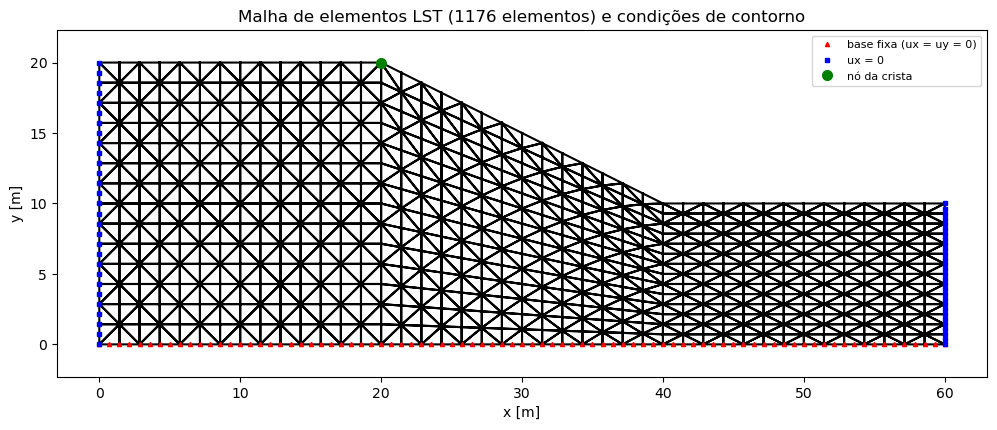

In [3]:
# ----- Topologia --------------------------------------------------------------
ElemNode, SysCoor, NodeSets, info = malha_talude_lst(superficie, y_base, dx_alvo)

nelem, nnode_element = ElemNode.shape
nnode = SysCoor.shape[0]

# Numeração 1-based -> índices do Python
ElemNode0 = ElemNode - 1
left_nodes0 = NodeSets["left"] - 1
right_nodes0 = NodeSets["right"] - 1
base_nodes0 = NodeSets["base"] - 1
surf_nodes0 = NodeSets["surface"] - 1

# Tabela de graus de liberdade do sistema: [ux, uy] de cada nó
SysDof = np.column_stack((2 * np.arange(nnode), 2 * np.arange(nnode) + 1))

ElemDof = np.zeros((nelem, 12), dtype=int)
for i in range(nelem):
    dofs = SysDof[ElemNode0[i, :], :].T
    ElemDof[i, :] = dofs.reshape(-1, order="F")

ndof = 2 * nnode
npoint = nelem * gaussorder

# ----- Coordenadas dos elementos ----------------------------------------------
ElemX = np.zeros((nelem, nnode_element))
ElemY = np.zeros((nelem, nnode_element))
for nodeno in range(nnode_element):
    ElemX[:, nodeno] = SysCoor[ElemNode0[:, nodeno], 0]
    ElemY[:, nodeno] = SysCoor[ElemNode0[:, nodeno], 1]

# ----- Condições de contorno cinemáticas (graus de liberdade restritos a zero) ----
#   base: ux = uy = 0  |  laterais: ux = 0 (apoio deslizante)
dof_fixos = np.concatenate((SysDof[base_nodes0, 0], SysDof[base_nodes0, 1],
                            SysDof[left_nodes0, 0], SysDof[right_nodes0, 0]))

# ----- Nó de monitoramento: crista do talude (último ponto na maior cota) --------
sup = np.asarray(superficie, dtype=float)
i_crista = int(np.max(np.where(sup[:, 1] == sup[:, 1].max())[0]))
i_pe = i_crista + int(np.argmin(sup[i_crista:, 1]))
xc_crista, yc_crista = sup[i_crista]
xc_pe, yc_pe = sup[i_pe]
no_crista = surf_nodes0[np.argmin(np.hypot(SysCoor[surf_nodes0, 0] - xc_crista,
                                           SysCoor[surf_nodes0, 1] - yc_crista))]
no_pe = surf_nodes0[np.argmin(np.hypot(SysCoor[surf_nodes0, 0] - xc_pe,
                                       SysCoor[surf_nodes0, 1] - yc_pe))]
H_talude = sup[:, 1].max() - sup[:, 1].min()

print(f"Malha: {nelem} elementos LST, {nnode} nós, {ndof} graus de liberdade "
      f"({info['nx']} colunas x {info['ny']} camadas)")
print(f"Graus de liberdade restritos: {np.unique(dof_fixos).size}")
print(f"Altura do talude H = {H_talude:.2f} m | nó da crista: {no_crista + 1} | nó do pé: {no_pe + 1}")

# ----- Figura: malha e apoios ---------------------------------------------------
plt.figure(figsize=(12, 4.5))
plt.gca().set_aspect("equal", adjustable="box")
elem_draw_2d(ElemX, ElemY, "-k", 3)
plt.plot(SysCoor[base_nodes0, 0], SysCoor[base_nodes0, 1], "r^", ms=3, label="base fixa (ux = uy = 0)")
plt.plot(SysCoor[left_nodes0, 0], SysCoor[left_nodes0, 1], "bs", ms=3, label="ux = 0")
plt.plot(SysCoor[right_nodes0, 0], SysCoor[right_nodes0, 1], "bs", ms=3)
plt.plot(SysCoor[no_crista, 0], SysCoor[no_crista, 1], "go", ms=7, label="nó da crista")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title(f"Malha de elementos LST ({nelem} elementos) e condições de contorno")
plt.legend(loc="upper right", fontsize=8)
plt.show()

## 3. Matriz de rigidez elástica, carga de peso próprio e pré-cálculos

- `hooke` fornece a matriz constitutiva elástica $\mathbf{D}$ (deformação plana, 4 componentes: $\sigma_x,\sigma_y,\sigma_z,\tau_{xy}$).
- A matriz de rigidez é montada com `k_lst` (rotina original) em formato **esparso**; a fatoração LU dos graus de
  liberdade livres é feita **uma única vez** e reaproveitada em todas as iterações.
- O peso próprio vira forças nodais equivalentes
  $\mathbf{f}_e=\sum_g W_g\,\mathbf{N}^T\mathbf{b}\,A\,t$ com $\mathbf{b}=(0,-\gamma)$.
- `montar_B_gauss` avalia a matriz $\mathbf{B}$ (`b_lst`) em todos os pontos de Gauss, para calcular
  deformações e forças internas de forma vetorizada.

In [4]:
XI, W = gauss_tri(gaussorder)

# --- Matriz constitutiva elástica ------------------------------------------------
D = hooke(s_type, E, nu)

psi_ef = min(psi, phi)                        # a dilatância não pode superar o ângulo de atrito

# --- Matriz de rigidez elástica (esparsa) e solver ----------------------------------
SysK = montar_K_esparsa(ElemX, ElemY, ElemDof, D, t, gaussorder, s_type)
solver = SolverApoios(SysK, dof_fixos)

# --- Forças de peso próprio (carga total, fator de gravidade = 1) --------------------
SysF = forcas_peso_proprio(ElemX, ElemY, ElemDof, ndof, gamma, t, gaussorder)

# --- Matrizes B, pesos de integração e coordenadas dos pontos de Gauss -----------------
Bg, wg, Xg, Yg = montar_B_gauss(ElemX, ElemY, gaussorder, s_type)

# --- Solução elástica (referência) -----------------------------------------------------
u_elastico = solver.resolver(SysF)

print(f"Peso total aplicado: {-SysF[1::2].sum():.1f} kN (por metro de espessura)")
print(f"Recalque elástico da crista: {-u_elastico[SysDof[no_crista, 1]] * 1000:.2f} mm")
if plastico:
    print(f"Mohr-Coulomb: c = {c:.2f} kPa | phi = {phi:.2f}° | psi = {psi_ef:.2f}°")

Peso total aplicado: 16200.0 kN (por metro de espessura)
Recalque elástico da crista: 57.94 mm
Mohr-Coulomb: c = 10.00 kPa | phi = 28.00° | psi = 0.00°


## 4. Procedimento incremental de aplicação do peso próprio

Para cada incremento de gravidade $\lambda_n = n/n_{step}$ (carga externa $\lambda_n\,\mathbf{f}_{g}$):

1. **Deformações**: $\Delta\boldsymbol\varepsilon = \mathbf{B}\,(\mathbf{u}^{k}-\mathbf{u}_n)$ em cada ponto de Gauss.
2. **Tensão tentativa** (preditor elástico): $\boldsymbol\sigma_{tr}=\boldsymbol\sigma_n+\mathbf{D}\,\Delta\boldsymbol\varepsilon$.
3. **Retorno plástico** (`retorno_mc`): nas tensões principais $\sigma_1\ge\sigma_2\ge\sigma_3$ (tração +), se
   $f=(1+\sin\phi)\sigma_1-(1-\sin\phi)\sigma_3-2c\cos\phi>0$ a tensão é levada à superfície de Mohr-Coulomb
   (fluxo não associado, $g=(1+\sin\psi)\sigma_1-(1-\sin\psi)\sigma_3$), tratando também as arestas e o ápice do cone.
4. **Resíduo**: $\mathbf{r}=\lambda_n\mathbf{f}_g-\sum_e\!\int\mathbf{B}^T\boldsymbol\sigma\,dV$.
   Se $\|\mathbf{r}\|/\|\lambda_n\mathbf{f}_g\|<tol$, o incremento está em equilíbrio; senão
   $\mathbf{u}^{k+1}=\mathbf{u}^{k}+\mathbf{K}_{el}^{-1}\mathbf{r}$ e volta-se ao passo 1
   (Newton-Raphson **modificado**, com a rigidez elástica).

Diferente do esquema *forward-Euler* do notebook original, aqui o equilíbrio é verificado a cada incremento
(sem deriva da superfície de escoamento). **Se as iterações não convergem**, a resistência do solo é
insuficiente para suportar o peso próprio: indício de ruptura do talude.

In [5]:
def equilibrar_etapa(fator_g, c_r, phi_r, psi_r, u_n, sig_n):
    '''
    Equilibra o talude sob o peso próprio multiplicado por `fator_g`, com a resistência
    (c_r, phi_r, psi_r), a partir do estado convergido anterior (u_n, sig_n).
    Newton-Raphson modificado: a rigidez elástica fatorada é reutilizada em todas as iterações.
    Retorna: u, tensões, pontos plásticos, forças internas, forças externas, convergiu, iterações, erro.
    '''
    SysFext = fator_g * SysF
    norma_f = np.linalg.norm(SysFext[solver.livres])
    uk = u_n.copy()

    for it in range(maxit):
        # --- Incremento de deformação e tensão tentativa (preditor elástico) -----------
        DeltaElemV = uk[ElemDof] - u_n[ElemDof]
        DeltaStrain = np.einsum("egsd,ed->egs", Bg, DeltaElemV)
        sig_trial = sig_n + DeltaStrain @ D.T

        # --- Retorno à superfície de escoamento ----------------------------------------
        if plastico:
            sig, pl = retorno_mc(sig_trial, E, nu, c_r, phi_r, psi_r)
        else:
            sig, pl = sig_trial, np.zeros(sig_trial.shape[:2], dtype=bool)

        # --- Forças internas e resíduo ----------------------------------------------------
        fe = np.einsum("egsd,egs,eg->ed", Bg, sig, wg * t)
        SysFint = np.bincount(ElemDof.ravel(), weights=fe.ravel(), minlength=ndof)
        residuo = SysFext - SysFint
        residuo[solver.fixos] = 0.0
        erro = np.linalg.norm(residuo) / norma_f
        if erro < tol:
            return uk, sig, pl, SysFint, SysFext, True, it + 1, erro

        # --- Correção dos deslocamentos (rigidez elástica fatorada) -----------------------
        uk = uk + solver.resolver(residuo)

    return uk, sig, pl, SysFint, SysFext, False, maxit, erro

In [6]:
# ----- Variáveis de estado e histórico -----------------------------------------------
u = np.zeros(ndof)                                    # deslocamentos totais
TotalStress = np.zeros((nelem, gaussorder, nsigma))   # [sx, sy, sz, txy] nos pontos de Gauss
pl_pts = np.zeros((nelem, gaussorder), dtype=bool)    # pontos plastificados (último incremento)

n_inc = nstep if plastico else 1
lam_hist = np.linspace(0.0, 1.0, n_inc + 1)           # fator de gravidade
Uhist = np.zeros(n_inc + 1)                           # recalque da crista [m]
convergiu = True

# ------------------------------------------------------------------------------------
# ----- Incrementação global da gravidade --------------------------------------------
# ------------------------------------------------------------------------------------
for incno in range(n_inc):
    u, TotalStress, pl_pts, SysFint, SysFext, inc_ok, nit, erro = equilibrar_etapa(
        lam_hist[incno + 1], c, phi, psi_ef, u, TotalStress)
    Uhist[incno + 1] = -u[SysDof[no_crista, 1]]

    print(f"incno = {incno + 1:2d}  gravidade = {lam_hist[incno + 1]:4.0%}  "
          f"iterações = {nit:3d}  erro = {erro:8.2e}  "
          f"pontos plásticos = {pl_pts.sum():5d}  recalque da crista = {Uhist[incno + 1] * 1000:7.2f} mm")

    if not inc_ok:
        convergiu = False
        print("\n*** SEM CONVERGÊNCIA neste incremento: o solo não suporta o peso próprio com a "
              "resistência adotada (possível ruptura do talude). ***")
        break

# ------------------------------------------------------------------------------------
# ----- Fim da incrementação -----------------------------------------------------------
# ------------------------------------------------------------------------------------
TotalElemV = u[ElemDof]                                    # deslocamentos por elemento
TotalStrain = np.einsum("egsd,ed->egs", Bg, TotalElemV)    # [ex, ey, ez, gxy]
Reacoes = SysFint - SysFext                                # reações nos apoios

incno =  1  gravidade =  10%  iterações =   2  erro = 2.00e-13  pontos plásticos =     0  recalque da crista =    5.79 mm
incno =  2  gravidade =  20%  iterações =   2  erro = 1.13e-13  pontos plásticos =     0  recalque da crista =   11.59 mm
incno =  3  gravidade =  30%  iterações =   2  erro = 8.29e-14  pontos plásticos =     0  recalque da crista =   17.38 mm
incno =  4  gravidade =  40%  iterações =   2  erro = 7.07e-14  pontos plásticos =     0  recalque da crista =   23.17 mm
incno =  5  gravidade =  50%  iterações =   2  erro = 5.88e-14  pontos plásticos =     0  recalque da crista =   28.97 mm
incno =  6  gravidade =  60%  iterações =   5  erro = 6.82e-06  pontos plásticos =     4  recalque da crista =   34.76 mm
incno =  7  gravidade =  70%  iterações =  12  erro = 8.79e-06  pontos plásticos =    24  recalque da crista =   40.56 mm
incno =  8  gravidade =  80%  iterações =  22  erro = 9.94e-06  pontos plásticos =    46  recalque da crista =   46.35 mm
incno =  9  gravidade = 

## 5. Verificações

1. **Geometria**: a soma das áreas dos elementos deve igualar a área do polígono do talude.
2. **Equilíbrio global**: a reação vertical total na base deve igualar o peso $\gamma\,A\,t$; a soma das reações horizontais
   deve ser nula.
3. **Perfil vertical longe do talude**: perto da fronteira esquerda o estado é quase unidimensional e
   $\sigma_y\approx-\gamma z$, em que $z$ é a profundidade abaixo da superfície.

Área do polígono = 900.0000 m2 | área da malha = 900.0000 m2
Reação vertical total = 16200.00 kN | peso aplicado = 16200.00 kN | diferença = 0.0000 %
Soma das reações horizontais = 2.258e-05 kN (deve ser ~ 0)


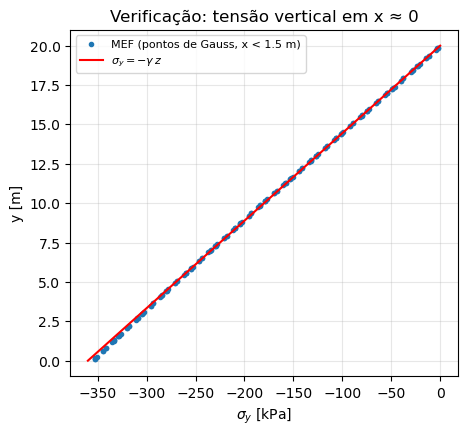

Razão sigma_y(MEF)/sigma_y(teórico): mín = 0.987 | máx = 1.011


In [7]:
# ----- 1) Área ---------------------------------------------------------------------------
poligono = np.vstack(([sup[0, 0], y_base], [sup[-1, 0], y_base], sup[::-1]))
area_pol = 0.5 * abs(np.sum(poligono[:, 0] * np.roll(poligono[:, 1], -1)
                            - np.roll(poligono[:, 0], -1) * poligono[:, 1]))
area_mef = wg.sum()
print(f"Área do polígono = {area_pol:.4f} m2 | área da malha = {area_mef:.4f} m2")

# ----- 2) Equilíbrio global ---------------------------------------------------------------
Ry_total = Reacoes[SysDof[:, 1]][np.isin(SysDof[:, 1], solver.fixos)].sum()
Rx_total = Reacoes[SysDof[:, 0]][np.isin(SysDof[:, 0], solver.fixos)].sum()
peso = gamma * area_pol * t * lam_hist[incno + 1]
print(f"Reação vertical total = {Ry_total:.2f} kN | peso aplicado = {peso:.2f} kN | "
      f"diferença = {100 * abs(Ry_total - peso) / peso:.4f} %")
print(f"Soma das reações horizontais = {Rx_total:.3e} kN (deve ser ~ 0)")

# ----- 3) Perfil sigma_y x profundidade perto da fronteira esquerda ------------------------
sel = Xg < sup[0, 0] + dx_alvo
z = sup[0, 1] - Yg[sel]
sy_mef = TotalStress[..., 1][sel]
sy_teo = -gamma * z
plt.figure(figsize=(5, 4.5))
plt.plot(sy_mef, Yg[sel], "o", ms=3, label="MEF (pontos de Gauss, x < %.1f m)" % (sup[0, 0] + dx_alvo))
zz = np.linspace(0, sup[0, 1] - y_base, 50)
plt.plot(-gamma * zz, sup[0, 1] - zz, "r-", label=r"$\sigma_y = -\gamma\, z$")
plt.xlabel(r"$\sigma_y$ [kPa]")
plt.ylabel("y [m]")
plt.title("Verificação: tensão vertical em x ≈ 0")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()
print(f"Razão sigma_y(MEF)/sigma_y(teórico): mín = {np.min(sy_mef[z > 1] / sy_teo[z > 1]):.3f} | "
      f"máx = {np.max(sy_mef[z > 1] / sy_teo[z > 1]):.3f}")

## 6. Deslocamentos e deformações

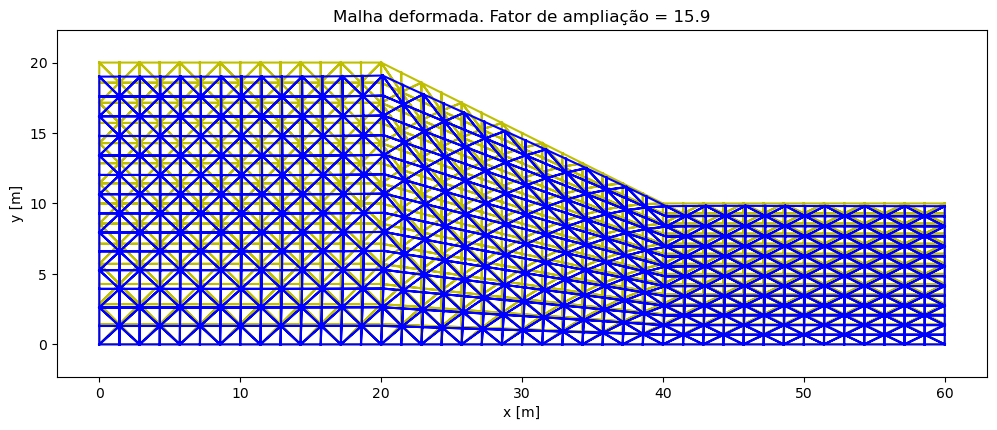

In [8]:
# ----- Malha deformada (ampliada) --------------------------------------------------------
plt.figure(figsize=(12, 4.5))
plt.gca().set_aspect("equal", adjustable="box")
mfak = 0.10                                    # deslocamento máximo = mfak * H após ampliação
elem_draw_2d(ElemX, ElemY, "-y", 3)
skalfak = plotflytning_v101(mfak, H_talude, ElemX, ElemY, TotalElemV)
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title(f"Malha deformada. Fator de ampliação = {skalfak:3.1f}")
plt.show()

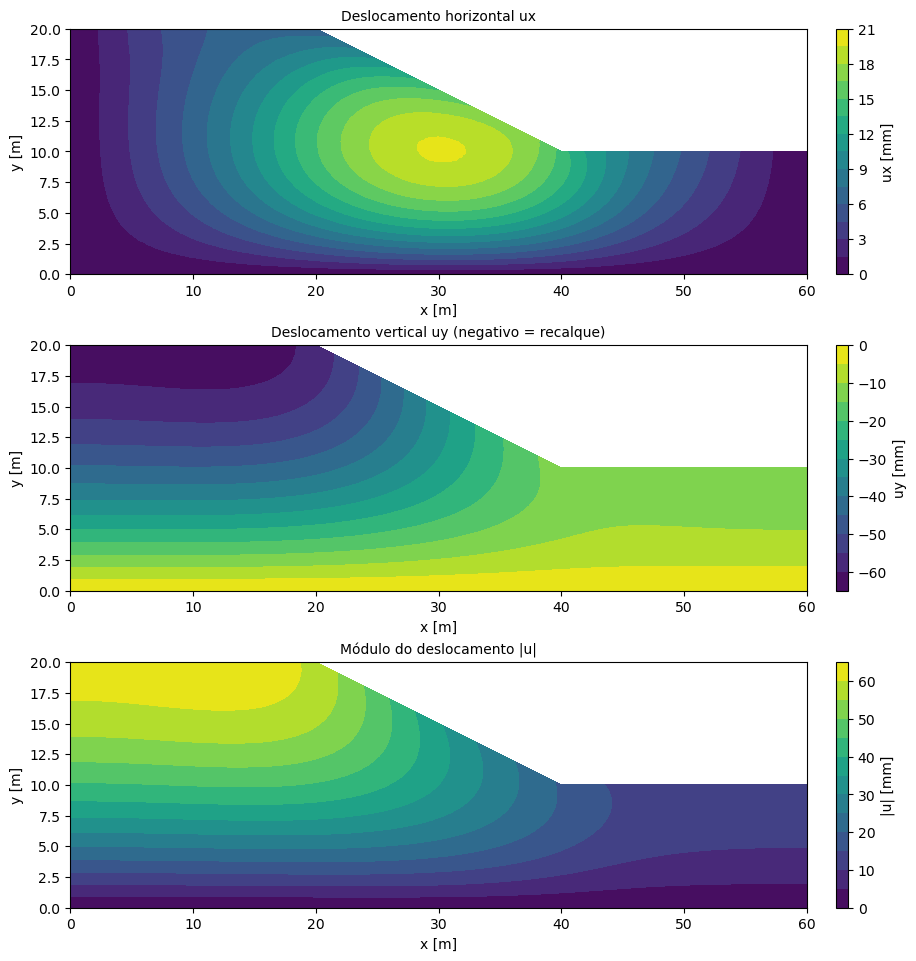

Recalque máximo = 62.98 mm | deslocamento horizontal máx. = 19.70 mm
Crista: ux = 6.57 mm, uy = -57.96 mm | Pé: ux = 14.35 mm, uy = -12.53 mm


In [9]:
# ----- Contornos de deslocamento ------------------------------------------------------------
ux = u[SysDof[:, 0]] * 1000          # [mm]
uy = u[SysDof[:, 1]] * 1000          # [mm]
umod = np.hypot(ux, uy)

fig, axs = plt.subplots(3, 1, figsize=(11, 9.5), constrained_layout=True)
plot_campo_nodal(SysCoor, ElemNode0, ux, ax=axs[0], titulo="Deslocamento horizontal ux", rotulo="ux [mm]")
plot_campo_nodal(SysCoor, ElemNode0, uy, ax=axs[1], titulo="Deslocamento vertical uy (negativo = recalque)", rotulo="uy [mm]")
plot_campo_nodal(SysCoor, ElemNode0, umod, ax=axs[2], titulo="Módulo do deslocamento |u|", rotulo="|u| [mm]")
for a in axs:
    a.set_xlabel("x [m]")
    a.set_ylabel("y [m]")
plt.show()

print(f"Recalque máximo = {-uy.min():.2f} mm | deslocamento horizontal máx. = {np.abs(ux).max():.2f} mm")
print(f"Crista: ux = {ux[no_crista]:.2f} mm, uy = {uy[no_crista]:.2f} mm | "
      f"Pé: ux = {ux[no_pe]:.2f} mm, uy = {uy[no_pe]:.2f} mm")

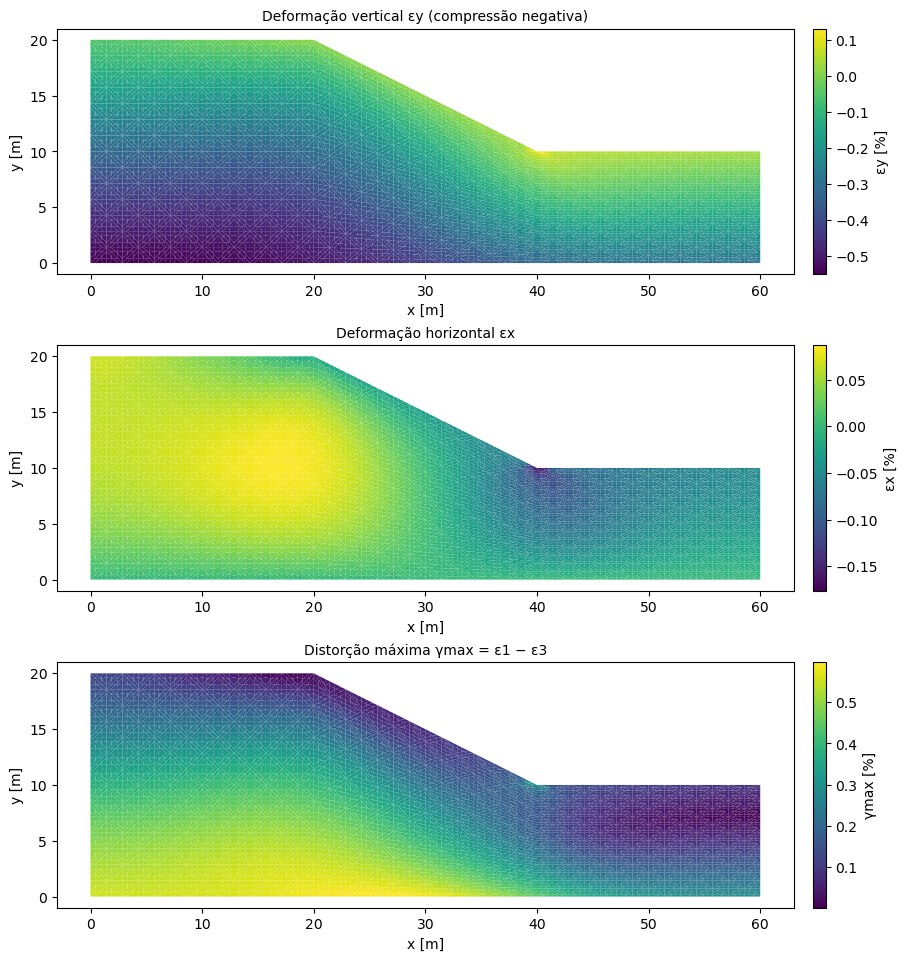

In [10]:
# ----- Deformações nos pontos de Gauss -----------------------------------------------------
ex, ey, gxy = TotalStrain[..., 0], TotalStrain[..., 1], TotalStrain[..., 3]
gmax = np.sqrt((ex - ey) ** 2 + gxy ** 2)      # distorção máxima no plano (e1 - e3)

fig, axs = plt.subplots(3, 1, figsize=(11, 9.5), constrained_layout=True)
plot_campo_gauss(ElemX, ElemY, 100 * ey, gaussorder, ax=axs[0], titulo="Deformação vertical εy (compressão negativa)", rotulo="εy [%]")
plot_campo_gauss(ElemX, ElemY, 100 * ex, gaussorder, ax=axs[1], titulo="Deformação horizontal εx", rotulo="εx [%]")
plot_campo_gauss(ElemX, ElemY, 100 * gmax, gaussorder, ax=axs[2], titulo="Distorção máxima γmax = ε1 − ε3", rotulo="γmax [%]")
for a in axs:
    a.set_xlabel("x [m]")
    a.set_ylabel("y [m]")
plt.show()

## 7. Tensões

Tração positiva. $\sigma_1$ é a tensão principal maior (menos compressiva) e $\sigma_3$ a menor (mais
compressiva) no plano; $\tau_{max}=(\sigma_1-\sigma_3)/2$.

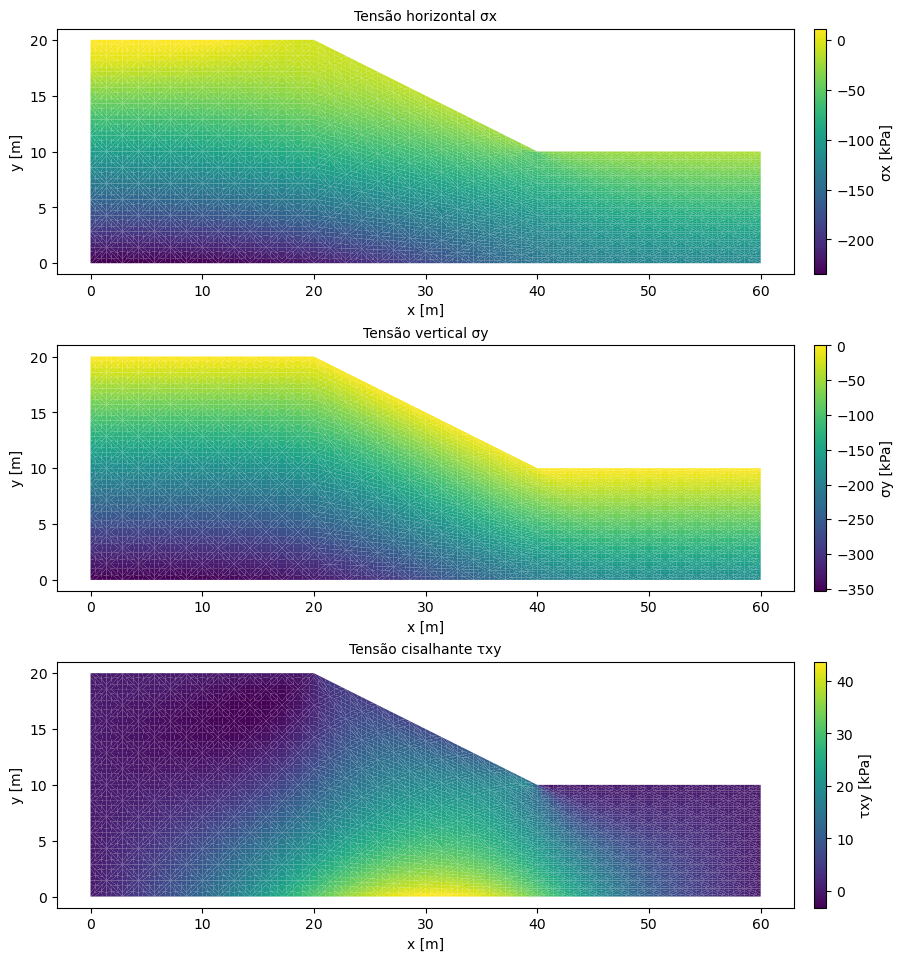

In [11]:
inv = invariantes(TotalStress, c, phi) if plastico else invariantes(TotalStress)

fig, axs = plt.subplots(3, 1, figsize=(11, 9.5), constrained_layout=True)
plot_campo_gauss(ElemX, ElemY, TotalStress[..., 0], gaussorder, ax=axs[0], titulo="Tensão horizontal σx", rotulo="σx [kPa]")
plot_campo_gauss(ElemX, ElemY, TotalStress[..., 1], gaussorder, ax=axs[1], titulo="Tensão vertical σy", rotulo="σy [kPa]")
plot_campo_gauss(ElemX, ElemY, TotalStress[..., 3], gaussorder, ax=axs[2], titulo="Tensão cisalhante τxy", rotulo="τxy [kPa]")
for a in axs:
    a.set_xlabel("x [m]")
    a.set_ylabel("y [m]")
plt.show()

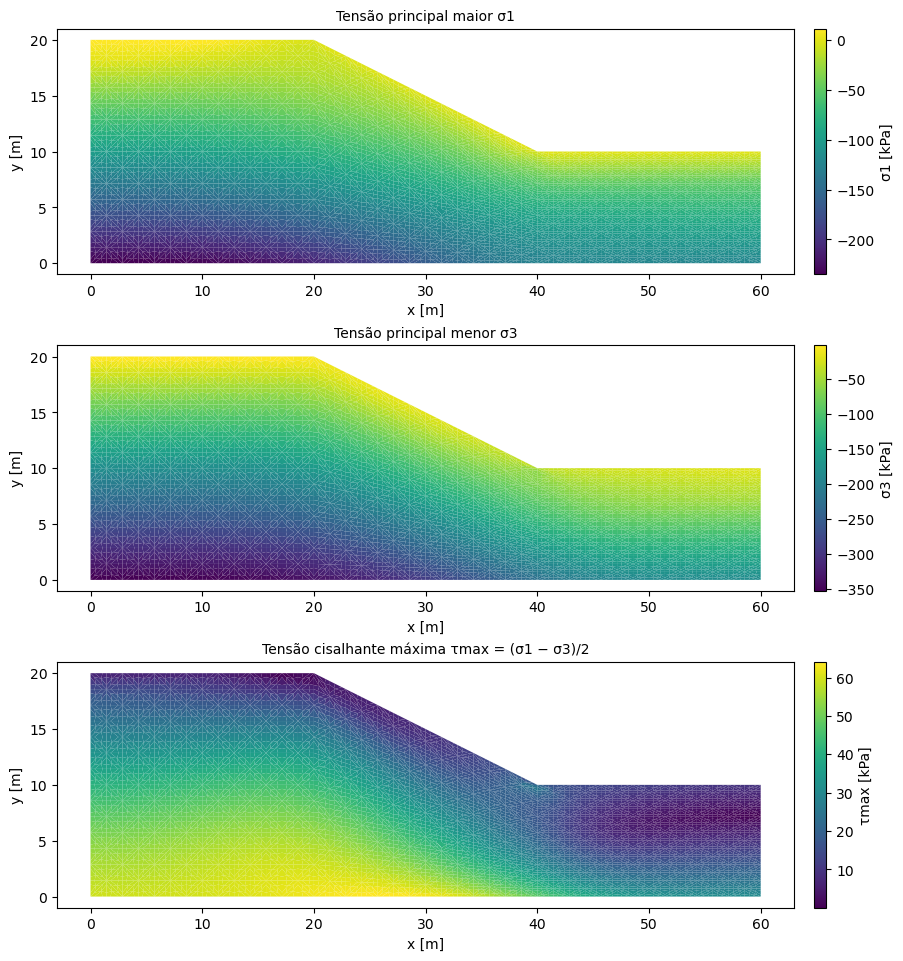

σy mínimo (maior compressão vertical) = -353.2 kPa | τmax máximo = 64.0 kPa | σ1 máximo = 11.3 kPa


In [12]:
fig, axs = plt.subplots(3, 1, figsize=(11, 9.5), constrained_layout=True)
plot_campo_gauss(ElemX, ElemY, inv["s1"], gaussorder, ax=axs[0], titulo="Tensão principal maior σ1", rotulo="σ1 [kPa]")
plot_campo_gauss(ElemX, ElemY, inv["s3"], gaussorder, ax=axs[1], titulo="Tensão principal menor σ3", rotulo="σ3 [kPa]")
plot_campo_gauss(ElemX, ElemY, inv["tmax"], gaussorder, ax=axs[2], titulo="Tensão cisalhante máxima τmax = (σ1 − σ3)/2", rotulo="τmax [kPa]")
for a in axs:
    a.set_xlabel("x [m]")
    a.set_ylabel("y [m]")
plt.show()

print(f"σy mínimo (maior compressão vertical) = {TotalStress[..., 1].min():.1f} kPa | "
      f"τmax máximo = {inv['tmax'].max():.1f} kPa | σ1 máximo = {inv['s1'].max():.1f} kPa")

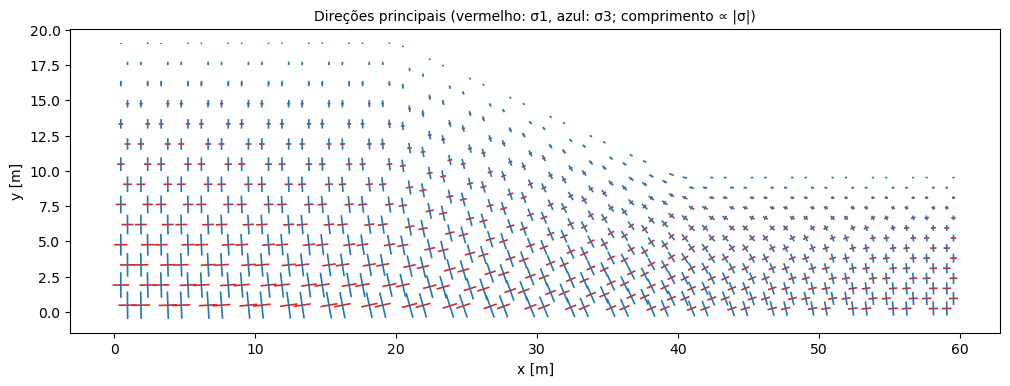

In [13]:
# ----- Direções principais de tensão (vermelho: σ1, azul: σ3) ----------------------------------
plt.figure(figsize=(12, 4.5))
plot_direcoes_principais(ElemX, ElemY, TotalStress, passo=2,
                         titulo="Direções principais (vermelho: σ1, azul: σ3; comprimento ∝ |σ|)")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.show()

## 8. Plastificação e curva gravidade × recalque

O **grau de mobilização** é $\dfrac{(\sigma_1-\sigma_3)/2}{c\cos\phi-\frac{\sigma_1+\sigma_3}{2}\sin\phi}$ (com $\sigma_1,\sigma_3$ as tensões principais
extremas, incluindo $\sigma_z$): vale 1 quando o ponto está sobre a superfície de Mohr-Coulomb (resistência totalmente
mobilizada) e 0 em estado hidrostático. A curva *fator de gravidade × recalque da crista* é o
análogo da curva carga-deslocamento do notebook original; o desvio em relação à reta elástica mostra a perda de
rigidez por plastificação.

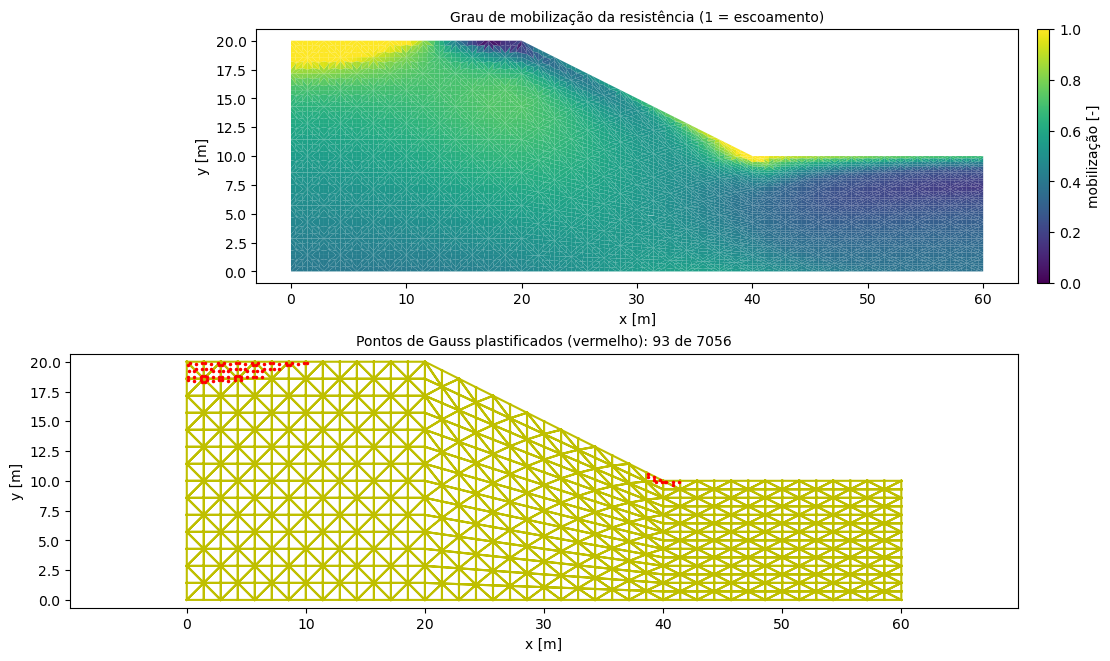

In [14]:
if plastico:
    fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), constrained_layout=True)
    plot_campo_gauss(ElemX, ElemY, inv["mob"], gaussorder, ax=ax[0], vmin=0, vmax=1,
                     titulo="Grau de mobilização da resistência (1 = escoamento)", rotulo="mobilização [-]")
    ax[1].set_aspect("equal", adjustable="box")
    elem_draw_2d(ElemX, ElemY, "-y", 3)
    ax[1].plot(Xg[pl_pts], Yg[pl_pts], "r.", ms=3)
    ax[1].set_title(f"Pontos de Gauss plastificados (vermelho): {pl_pts.sum()} de {npoint}", fontsize=10)
    for a in ax:
        a.set_xlabel("x [m]")
        a.set_ylabel("y [m]")
    plt.show()
else:
    print("Modelo elástico: não há plastificação.")

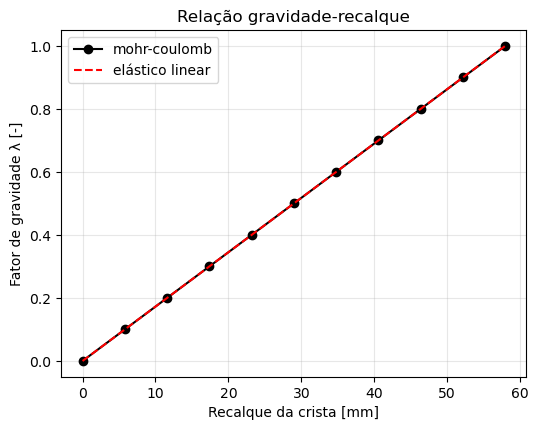

In [15]:
# ----- Curva gravidade x recalque da crista --------------------------------------------------
plt.figure(figsize=(6, 4.5))
n_ok = incno + 2 if convergiu else incno + 1
plt.plot(Uhist[:n_ok] * 1000, lam_hist[:n_ok], "ko-", label=modelo)
rec_el = -u_elastico[SysDof[no_crista, 1]]
plt.plot([0, rec_el * 1000], [0, 1], "r--", label="elástico linear")
plt.xlabel("Recalque da crista [mm]")
plt.ylabel("Fator de gravidade λ [-]")
plt.title("Relação gravidade-recalque")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 9. Fator de segurança por redução de resistência (opcional)

Partindo do estado de equilíbrio sob o peso próprio (resistência real), a resistência é reduzida por um fator
$SRF$: $c_r=c/SRF$ e $\tan\phi_r=\tan\phi/SRF$, mantendo a gravidade total. Cada $SRF$ é equilibrado com
`equilibrar_etapa` (a tensão que excede o novo critério é redistribuída). O **menor $SRF$ para o qual as iterações não
convergem** estima o fator de segurança $FS$ do talude e o campo de deslocamentos incrementais mostra o
mecanismo de ruptura. Os $SRF$ de `srf_lista` são testados em sequência até a primeira falha; depois o intervalo é refinado por
bissecção (`n_refina`). Para desativar, use `calcular_fs = False`.

In [16]:
fs_inf, fs_sup = None, None            # intervalo do fator de segurança [FS_inf, FS_sup]
if calcular_fs and plastico and convergiu:
    estado_ok = (u.copy(), TotalStress.copy(), pl_pts.copy())      # fim da gravidade (SRF = 1)
    srf_ok, srf_falha = 1.0, None
    srf_hist, rec_hist = [1.0], [-u[SysDof[no_crista, 1]] * 1000]

    def reduz_e_equilibra(srf):
        c_r = c / srf
        phi_r = np.degrees(np.arctan(np.tan(np.radians(phi)) / srf))
        saida = equilibrar_etapa(1.0, c_r, phi_r, min(psi, phi_r), estado_ok[0], estado_ok[1])
        print(f"SRF = {srf:5.3f}  (c = {c_r:5.2f} kPa, phi = {phi_r:5.2f}°)  "
              f"iterações = {saida[6]:3d}  erro = {saida[7]:8.2e}  "
              f"{'convergiu' if saida[5] else 'NÃO CONVERGIU'}")
        return saida

    for srf in srf_lista:                                          # varredura inicial
        u_s, sig_s, pl_s, _, _, ok, _, _ = reduz_e_equilibra(srf)
        if not ok:
            srf_falha = srf
            break
        estado_ok, srf_ok = (u_s, sig_s, pl_s), srf
        srf_hist.append(srf)
        rec_hist.append(-u_s[SysDof[no_crista, 1]] * 1000)

    if srf_falha is not None:                                      # refinamento por bissecção
        for _ in range(n_refina):
            srf = 0.5 * (srf_ok + srf_falha)
            u_s, sig_s, pl_s, _, _, ok, _, _ = reduz_e_equilibra(srf)
            if ok:
                estado_ok, srf_ok = (u_s, sig_s, pl_s), srf
                srf_hist.append(srf)
                rec_hist.append(-u_s[SysDof[no_crista, 1]] * 1000)
            else:
                srf_falha = srf

    fs_inf, fs_sup = srf_ok, srf_falha
    if fs_sup is None:
        print(f"\nTodos os SRF testados convergiram: FS > {fs_inf:.2f}. Aumente `srf_lista`.")
    else:
        print(f"\nFator de segurança (redução de resistência): {fs_inf:.3f} <= FS < {fs_sup:.3f}")
else:
    print("Seção ignorada (calcular_fs = False, modelo elástico ou gravidade sem convergência).")

SRF = 1.200  (c =  8.33 kPa, phi = 23.90°)  iterações =  46  erro = 9.53e-06  convergiu
SRF = 1.400  (c =  7.14 kPa, phi = 20.80°)  iterações = 184  erro = 9.99e-06  convergiu
SRF = 1.600  (c =  6.25 kPa, phi = 18.38°)  iterações = 322  erro = 9.94e-06  convergiu
SRF = 1.800  (c =  5.56 kPa, phi = 16.46°)  iterações = 500  erro = 4.45e-04  NÃO CONVERGIU
SRF = 1.700  (c =  5.88 kPa, phi = 17.37°)  iterações = 358  erro = 9.95e-06  convergiu
SRF = 1.750  (c =  5.71 kPa, phi = 16.90°)  iterações = 312  erro = 9.87e-06  convergiu
SRF = 1.775  (c =  5.63 kPa, phi = 16.68°)  iterações = 500  erro = 2.12e-05  NÃO CONVERGIU

Fator de segurança (redução de resistência): 1.750 <= FS < 1.775


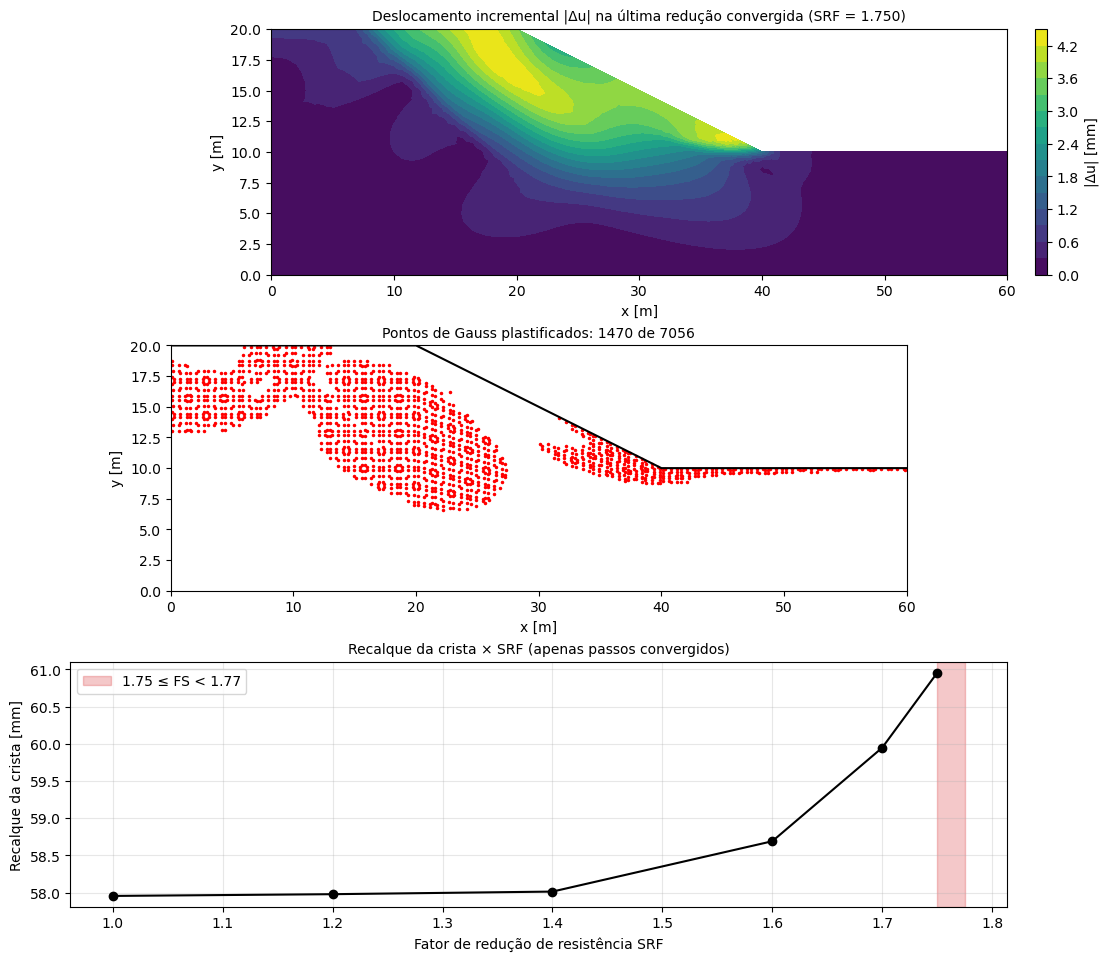

In [17]:
if fs_inf is not None and len(srf_hist) > 1:
    u_srf, sig_srf, pl_srf = estado_ok
    dU = (u_srf - u)
    dmod = np.hypot(dU[SysDof[:, 0]], dU[SysDof[:, 1]]) * 1000      # [mm], incremento desde a gravidade

    fig = plt.figure(figsize=(11, 9.5), constrained_layout=True)
    gs = fig.add_gridspec(3, 2, width_ratios=[1, 0.001])
    ax1 = fig.add_subplot(gs[0, 0])
    plot_campo_nodal(SysCoor, ElemNode0, dmod, ax=ax1,
                     titulo=f"Deslocamento incremental |Δu| na última redução convergida (SRF = {fs_inf:.3f})",
                     rotulo="|Δu| [mm]")
    ax2 = fig.add_subplot(gs[1, 0])
    ax2.set_aspect("equal", adjustable="box")
    ax2.plot(Xg[pl_srf], Yg[pl_srf], "r.", ms=3)
    ax2.plot(sup[:, 0], sup[:, 1], "k-")
    ax2.set_xlim(sup[0, 0], sup[-1, 0])
    ax2.set_ylim(y_base, sup[:, 1].max())
    ax2.set_title(f"Pontos de Gauss plastificados: {pl_srf.sum()} de {npoint}", fontsize=10)
    for a in (ax1, ax2):
        a.set_xlabel("x [m]")
        a.set_ylabel("y [m]")
    ax3 = fig.add_subplot(gs[2, 0])
    ordem = np.argsort(srf_hist)
    ax3.plot(np.array(srf_hist)[ordem], np.array(rec_hist)[ordem], "ko-")
    if fs_sup is not None:
        ax3.axvspan(fs_inf, fs_sup, color="tab:red", alpha=0.25, label=f"{fs_inf:.2f} ≤ FS < {fs_sup:.2f}")
        ax3.legend()
    ax3.set_xlabel("Fator de redução de resistência SRF")
    ax3.set_ylabel("Recalque da crista [mm]")
    ax3.set_title("Recalque da crista × SRF (apenas passos convergidos)", fontsize=10)
    ax3.grid(alpha=0.3)
    plt.show()

## 10. Resumo

In [18]:
print("=" * 62)
print("RESUMO DA ANÁLISE DE TENSÕES E DEFORMAÇÕES - TALUDE (PESO PRÓPRIO)")
print("=" * 62)
print(f"Malha: {nelem} elementos LST | {nnode} nós | {ndof} graus de liberdade")
print(f"Solo: gamma = {gamma} kN/m3 | E = {E / 1e3:.1f} MPa | nu = {nu}")
if plastico:
    print(f"      c = {c} kPa | phi = {phi}° | psi = {psi_ef}°")
print(f"Modelo: {modelo}")
print(f"Convergência: {'SIM' if convergiu else 'NÃO (possível ruptura)'}")
print("-" * 62)
print(f"Recalque máximo       = {-uy.min():8.2f} mm")
print(f"Recalque da crista    = {-uy[no_crista]:8.2f} mm")
print(f"Desloc. horiz. do pé  = {ux[no_pe]:8.2f} mm")
print(f"σy mínimo             = {TotalStress[..., 1].min():8.1f} kPa")
print(f"τmax máximo           = {inv['tmax'].max():8.1f} kPa")
if plastico:
    print(f"Pontos plastificados  = {pl_pts.sum():8d} de {npoint}")
if fs_inf is not None:
    print("-" * 62)
    print("FS (redução de resistência) = " + (f"{fs_inf:.3f} a {fs_sup:.3f}" if fs_sup else f"> {fs_inf:.2f}"))

RESUMO DA ANÁLISE DE TENSÕES E DEFORMAÇÕES - TALUDE (PESO PRÓPRIO)
Malha: 1176 elementos LST | 2465 nós | 4930 graus de liberdade
Solo: gamma = 18.0 kN/m3 | E = 30.0 MPa | nu = 0.4
      c = 10.0 kPa | phi = 28.0° | psi = 0.0°
Modelo: mohr-coulomb
Convergência: SIM
--------------------------------------------------------------
Recalque máximo       =    62.98 mm
Recalque da crista    =    57.96 mm
Desloc. horiz. do pé  =    14.35 mm
σy mínimo             =   -353.2 kPa
τmax máximo           =     64.0 kPa
Pontos plastificados  =       93 de 7056
--------------------------------------------------------------
FS (redução de resistência) = 1.750 a 1.775


### Notas e extensões

- **Comparação com o equilíbrio limite:** para a geometria e o solo padrão ($\gamma=18$ kN/m³, $c=10$ kPa, $\phi=28^\circ$) o notebook de
  Bishop Simplificado fornece $FS=1{,}83$. Com os parâmetros padrão deste notebook (malha de 1,5 m, $\nu=0{,}40$, $\psi=0$) a seção 9 deu
  $1{,}75\le FS<1{,}78$ (diferença de cerca de 4 %, de ordem esperada entre métodos distintos).
- **Sensibilidade ao coeficiente de Poisson (importante na seção 9):** como a gravidade é aplicada sobre apoios laterais deslizantes, o estado
  de tensões longe do talude é $K_0=\nu/(1-\nu)$. Se $K_0$ ficar abaixo do coeficiente de empuxo ativo
  $K_a=\tan^2(45^\circ-\phi_r/2)$ da resistência reduzida, a própria coluna de solo distante do talude plastifica e as iterações deixam de convergir
  **sem que haja ruptura do talude**. Com os dados padrão, o mesmo cálculo resultou em $FS\approx1{,}40$ para $\nu=0{,}35$ ($K_0=0{,}54$),
  $1{,}75$ para $\nu=0{,}40$ ($K_0=0{,}67$) e $1{,}80$ para $\nu=0{,}45$. Portanto, para estimar o $FS$ use $K_0 \gtrsim K_a(\phi_r)$ no maior $SRF$ esperado
  (ou, melhor, imponha um estado inicial de tensões com $K_0$ prescrito).
- **Estado inicial de tensões:** a gravidade é aplicada a partir de tensões nulas, sobre o talude já formado (procedimento
  simples; o coeficiente de empuxo ao repouso resultante é $K_0=\nu/(1-\nu)$). Para a história de tensões real
  (construção/escavação, $K_0$ específico) é preciso gerar o estado geostático antes e aplicar a escavação em etapas.
- **Poropressão, camadas de solo e cargas adicionais** (sobrecarga na crista, etc.) podem ser acrescentados: camadas =
  propriedades por elemento; sobrecarga = forças nodais equivalentes em `SysF`.
- **Solver de apoios:** `SolverApoios` usa numeração 0-based dos graus de liberdade (`SysDof`) e restringe valores nulos.
  Isso difere de `solveq` de `rotinas_MEF.py`, que subtrai 1 dos números de grau de liberdade (convenção do Matlab):
  ao chamar `solveq` com `SysDof` 0-based, o conjunto de graus de liberdade restritos fica deslocado em uma posição.